# 2 · Dar valor a las acciones: de Bellman a Q-learning

**Lectura acompañada:** §§2.1–2.5, pp. 31–50 de [Murphy, v5](https://arxiv.org/abs/2412.05265v5). Requisitos: retorno descontado, esperanza y arrays. Aquí construiremos un entorno, resolveremos su modelo y después aprenderemos solo de muestras.

**Objetivo:** que puedas explicar cada término de una actualización de Q y distinguir tres preguntas: ¿estima bien los valores?, ¿elige buenas acciones?, ¿qué datos ha utilizado?

El cuaderno es autónomo: NumPy y Matplotlib bastan. Los experimentos ampliados de esta lección tienen su propio presupuesto; no deben confundirse con las cifras de la ejecución de referencia guardada en resultados/.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
GAMMA = 0.95
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})


## 1. §2.1 · Valor de estado, valor de acción y ventaja

$V^\pi(s)$ responde cuánto retorno esperamos si empezamos en $s$ y seguimos $\pi$. $Q^\pi(s,a)$ obliga a ejecutar primero $a$ y después sigue la política. La ventaja compara esa acción con el promedio de la política:

$$V^\pi(s)=\sum_a\pi(a|s)Q^\pi(s,a),\qquad A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s).$$

No son recompensas instantáneas. Una acción sin premio inmediato puede tener alto valor por las oportunidades que abre. Tampoco son propiedades del estado sin más: dependen de la política, del descuento y del modelo de recompensas.

La ecuación de Bellman separa la primera transición del resto:

$$Q^\pi(s,a)=\sum_{s'}P(s'|s,a)[R(s,a,s')+\gamma V^\pi(s')].$$

Para buscar la mejor política, el valor futuro usa un máximo sobre acciones. Para evaluar una política fija, utiliza su promedio. Confundir ambas operaciones es cambiar la pregunta a mitad del cálculo.

## 2. Nuestro mundo de siete posiciones

Las posiciones 0 y 6 son terminales. Al entrar en 6 recibimos 1; las demás transiciones desde estados interiores cuestan 0.01. Una orden de ir a la derecha se invierte con probabilidad 0.15. Después de terminar, la recompensa es cero.

La matriz P tiene forma estado × acción × siguiente estado. R almacena recompensas por transición. Este modelo lo usará el planificador y el evaluador, mientras que el aprendiz recibirá únicamente transiciones muestreadas.


In [2]:
def construir_cadena(n=7, deslizamiento=0.15):
    P = np.zeros((n, 2, n))
    R = np.zeros_like(P)
    for s in range(1, n - 1):
        for a in range(2):
            for ejecutada, prob in [(a, 1-deslizamiento), (1-a, deslizamiento)]:
                siguiente = s + (1 if ejecutada == 1 else -1)
                P[s, a, siguiente] += prob
                R[s, a, siguiente] = 1.0 if siguiente == n-1 else -0.01
    P[0, :, 0] = 1
    P[-1, :, -1] = 1
    return P, R

P, R = construir_cadena()
assert np.allclose(P.sum(axis=2), 1)
print("P(siguiente | estado=3, derecha):", P[3, 1])
print("Recompensa al llegar a meta:", R[5, 1, 6])


P(siguiente | estado=3, derecha): [0.   0.   0.15 0.   0.85 0.   0.  ]
Recompensa al llegar a meta: 1.0


## 3. §2.2 · Resolver Bellman cuando conocemos el modelo

La iteración de valor empieza con una conjetura y aplica el operador de optimalidad. Cada pasada propaga consecuencias un paso más lejos. Con un MDP finito descontado, el operador es una contracción en norma máximo: las diferencias se reducen al menos por el factor $\gamma$.

Eso garantiza convergencia en este caso, pero no elimina el coste de representar todos los estados. La iteración de políticas alterna evaluación completa y mejora greedy. RTDP concentra actualizaciones en estados visitados o relevantes.

Primero observa cómo se propaga la recompensa desde la derecha. No estamos recogiendo experiencia: estamos calculando con P y R.


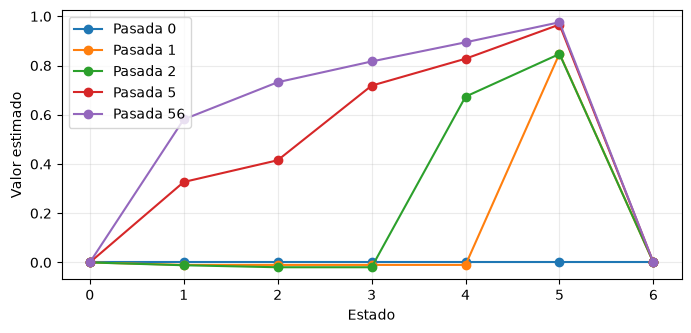

V óptimo: [0.     0.5813 0.7323 0.8166 0.8945 0.976  0.    ]


In [3]:
def resolver(P, R, gamma=GAMMA):
    V = np.zeros(len(P))
    historia = [V.copy()]
    for _ in range(10000):
        Q = np.sum(P * (R + gamma * V[None, None, :]), axis=2)
        nuevo = Q.max(axis=1)
        historia.append(nuevo.copy())
        if np.max(np.abs(nuevo - V)) < 1e-12:
            return nuevo, Q, np.array(historia)
        V = nuevo
    raise RuntimeError("Bellman no convergió")

V_opt, Q_opt, historia = resolver(P, R)
for i in [0, 1, 2, 5, len(historia)-1]:
    plt.plot(historia[i], "o-", label=f"Pasada {i}")
plt.xlabel("Estado")
plt.ylabel("Valor estimado")
plt.legend()
plt.show()
print("V óptimo:", V_opt)
assert np.allclose(V_opt[[0, -1]], 0)


La condición terminal importa. El valor de estar ya en el terminal es cero aunque entrar en la meta produzca 1. Si asignásemos recompensa 1 repetidamente al permanecer allí, resolveríamos otro problema.

## 4. §2.3 · Reemplazar esperanzas por muestras

Monte Carlo espera al episodio completo y usa el retorno observado. TD(0) actualiza con $r+\gamma V(s')$. El segundo método arranca antes, pero confía en una estimación que también puede estar equivocada: eso es bootstrap.

Los retornos de $n$ pasos interpolan entre ambos. Reúnen $n$ recompensas y luego añaden el valor estimado, salvo si han alcanzado un terminal. TD($\lambda$) mezcla horizontes; las trazas de elegibilidad permiten asignar crédito hacia atrás sin guardar y reprocesar todos los episodios.

La siguiente trayectoria llega a la meta en tres transiciones. Comparamos objetivos para el primer estado, sin afirmar que una única muestra permita comparar varianzas.


In [4]:
recompensas = np.array([-0.01, -0.01, 1.0])
valores = np.array([0.20, 0.40, 0.60, 0.0])

def objetivo_n_pasos(r, v, n, gamma=GAMMA):
    m = min(n, len(r))
    acumulado = np.dot(gamma**np.arange(m), r[:m])
    bootstrap = gamma**m * v[m] if m < len(r) else 0.0
    return float(acumulado + bootstrap)

for n in [1, 2, 3]:
    print(f"Objetivo a {n} pasos: {objetivo_n_pasos(recompensas, valores, n):.4f}")
mc = np.dot(GAMMA**np.arange(3), recompensas)
assert np.isclose(objetivo_n_pasos(recompensas, valores, 3), mc)


Objetivo a 1 pasos: 0.3700
Objetivo a 2 pasos: 0.5220
Objetivo a 3 pasos: 0.8830


TD no significa necesariamente sesgo permanente: bajo condiciones tabulares adecuadas puede converger al valor correcto. El intercambio entre sesgo, varianza y velocidad depende de las estimaciones actuales, del horizonte y de los datos.

## 5. §§2.4–2.5 · SARSA y Q-learning responden preguntas distintas

SARSA usa la siguiente acción realmente elegida: $r+\gamma Q(s',a')$. Q-learning usa $r+\gamma\max_b Q(s',b)$. Si la política de comportamiento explora, esos objetivos pueden diferir mucho.

Por ejemplo, SARSA puede aprender que acercarse a un precipicio es peligroso porque contempla las futuras acciones exploratorias. Q-learning estima la continuación greedy, aunque sus datos provengan de una política exploratoria. Ese es el sentido de off-policy aquí; no significa que podamos ignorar la cobertura de acciones.


In [5]:
q_siguiente = np.array([0.2, 0.9])
accion_exploratoria = 0
premio = -0.01
sarsa = premio + GAMMA * q_siguiente[accion_exploratoria]
qlearning = premio + GAMMA * q_siguiente.max()
print("Objetivo SARSA:", sarsa)
print("Objetivo Q-learning:", qlearning)

def actualizar_q(Q, s, a, r, siguiente, terminal, alpha, gamma=GAMMA):
    objetivo = r + gamma * (not terminal) * Q[siguiente].max()
    Q[s, a] += alpha * (objetivo - Q[s, a])

prueba = np.zeros((2, 2))
prueba[1] = 100  # Debe ignorarse si la transición termina.
actualizar_q(prueba, 0, 0, 1, 1, True, alpha=1.0)
assert prueba[0, 0] == 1


Objetivo SARSA: 0.18
Objetivo Q-learning: 0.845


## 6. Aprender únicamente de interacciones

El entorno encapsula el muestreo con el modelo; la función de entrenamiento no consulta P, R ni Q óptimo. La tasa $N(s,a)^{-0.6}$ disminuye con las visitas. Usamos exploración persistente y desempate aleatorio para no privilegiar siempre la izquierda al empezar con ceros.

Los episodios arrancan en un estado interior aleatorio. Medimos presupuesto en transiciones, no en episodios de duración desigual.


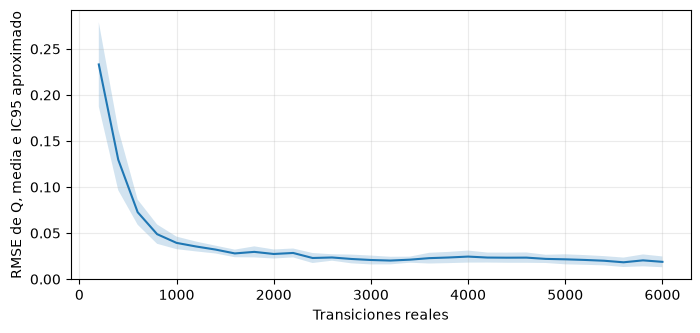

In [6]:
def crear_entorno(P, R):
    def paso(s, a, rng):
        siguiente = int(rng.choice(len(P), p=P[s, a]))
        return siguiente, R[s, a, siguiente], siguiente in (0, len(P)-1)
    return paso

def aprender(paso, n_estados, seed, pasos=6000, epsilon=0.25):
    rng = np.random.default_rng(seed)
    Q = np.zeros((n_estados, 2))
    visitas = np.zeros_like(Q)
    registros = []
    s = int(rng.integers(1, n_estados-1))
    for t in range(1, pasos+1):
        mejores = np.flatnonzero(np.isclose(Q[s], Q[s].max(), atol=1e-12, rtol=0))
        a = int(rng.integers(2) if rng.random() < epsilon else rng.choice(mejores))
        siguiente, premio, terminal = paso(s, a, rng)
        visitas[s, a] += 1
        actualizar_q(Q, s, a, premio, siguiente, terminal, visitas[s, a]**-0.6)
        s = int(rng.integers(1, n_estados-1)) if terminal else siguiente
        if t % 200 == 0:
            registros.append(Q.copy())
    return np.array(registros), visitas

paso = crear_entorno(P, R)
corridas = np.array([aprender(paso, len(P), SEMILLA+k)[0] for k in range(12)])
errores = np.sqrt(((corridas[:, :, 1:-1] - Q_opt[None, None, 1:-1])**2).mean(axis=(2, 3)))
x = np.arange(1, errores.shape[1]+1) * 200
media = errores.mean(axis=0)
banda = 1.96 * errores.std(axis=0, ddof=1) / np.sqrt(len(errores))
plt.plot(x, media)
plt.fill_between(x, media-banda, media+banda, alpha=0.2)
plt.xlabel("Transiciones reales")
plt.ylabel("RMSE de Q, media e IC95 aproximado")
plt.show()


## 7. Estimar bien y decidir bien no son lo mismo

Un error de Q pequeño es útil, pero la política solo necesita ordenar correctamente las acciones relevantes. Podemos equivocarnos algo en ambos valores y aun así escoger la mejor acción.

Para medirlo evaluamos exactamente la política greedy aprendida. Resolver el sistema lineal pertenece al evaluador; no se utiliza para actualizar al agente. En problemas grandes necesitaríamos otra forma de evaluación independiente.


In [7]:
def evaluar(P, R, politica, gamma=GAMMA):
    filas = np.arange(len(P))
    transiciones = P[filas, politica]
    recompensa_media = (transiciones * R[filas, politica]).sum(axis=1)
    return np.linalg.solve(np.eye(len(P)) - gamma * transiciones, recompensa_media)

rendimientos = [evaluar(P, R, q[-1].argmax(axis=1))[3] for q in corridas]
print("Valor óptimo desde 3:", V_opt[3])
print("Valor medio aprendido:", np.mean(rendimientos))
print("RMSE medio final:", errores[:, -1].mean())
assert max(rendimientos) <= V_opt[3] + 1e-9


Valor óptimo desde 3: 0.8166195128234138
Valor medio aprendido: 0.8166195128236943
RMSE medio final: 0.018778378177444557


## 8. §2.5 · El máximo también selecciona ruido

Supón que diez acciones tienen valor real cero, pero estimamos cada una con ruido de media cero. La mayor estimación suele ser positiva. El sesgo no procede de una recompensa mal definida; lo introduce seleccionar el máximo.

Double Q separa la estimación que elige de la que evalúa. Si ambas son independientes en este ejemplo, la evaluación del ganador vuelve a tener media cero. Las redes reales pueden tener errores correlacionados, por lo que esta demostración ideal no garantiza eliminar todo sesgo en Double DQN.


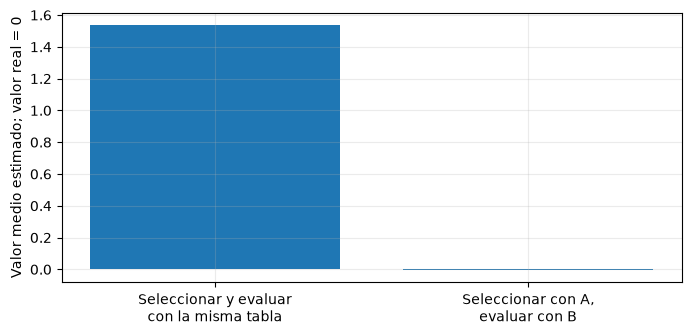

Mismo estimador: 1.5386257922438322 Estimadores separados: -0.002749643956369881


In [8]:
rng = np.random.default_rng(SEMILLA)
estimador_a = rng.normal(size=(30000, 10))
estimador_b = rng.normal(size=(30000, 10))
ganador = estimador_a.argmax(axis=1)
optimista = estimador_a.max(axis=1)
separado = estimador_b[np.arange(len(ganador)), ganador]
plt.bar(["Seleccionar y evaluar\ncon la misma tabla", "Seleccionar con A,\nevaluar con B"],
        [optimista.mean(), separado.mean()])
plt.ylabel("Valor medio estimado; valor real = 0")
plt.show()
print("Mismo estimador:", optimista.mean(), "Estimadores separados:", separado.mean())


## 9. De las tablas a DQN, Rainbow y HER

Una red aproxima Q cuando la tabla no cabe o queremos generalizar. Pero una actualización modifica muchos estados a la vez. La combinación de aproximación funcional, bootstrap y datos off-policy puede ser inestable: es la tríada mortal.

DQN utiliza un buffer de replay y una red objetivo que cambia más despacio. El primero reutiliza experiencia y altera sus correlaciones; la segunda reduce el movimiento del objetivo de entrenamiento. Replay priorizado cambia el muestreo y requiere tratar su sesgo. Dueling separa valor y ventaja; noisy nets modifican la exploración; los objetivos de varios pasos cambian el horizonte del crédito. Rainbow combina varias piezas y BBF estudia decisiones adicionales de entrenamiento. Ninguna de estas etiquetas sustituye a especificar qué pérdida y datos se usan.

En acciones continuas, encontrar el máximo sobre acciones deja de ser una búsqueda pequeña. Eso motivará actores explícitos en el capítulo 3.

HER responde a otro problema: una trayectoria que no alcanzó la meta solicitada puede aportar datos sobre una meta que sí alcanzó. Se conserva la transición y se recalcula la recompensa para la nueva meta. No basta con cambiar el nombre de la meta sin actualizar las señales asociadas.


In [9]:
trayectoria = np.array([1, 2, 3, 4])
meta_original, meta_reetiquetada = 6, 4
r_original = (trayectoria[1:] == meta_original).astype(float)
r_nueva = (trayectoria[1:] == meta_reetiquetada).astype(float)
print("Mismas posiciones:", trayectoria)
print("Recompensas para meta 6:", r_original)
print("Recompensas para meta 4:", r_nueva)


Mismas posiciones: [1 2 3 4]
Recompensas para meta 6: [0. 0. 0.]
Recompensas para meta 4: [0. 0. 1.]


## 10. Tu experimento y una solución orientativa

Modifica el deslizamiento y el presupuesto. Antes de ejecutar, separa dos predicciones: cómo cambiará el problema óptimo y cómo cambiará la dificultad de aprenderlo. Comparar contra el Q óptimo del entorno anterior sería un error de evaluación.


In [10]:
DESLIZAMIENTO = 0.30
P2, R2 = construir_cadena(deslizamiento=DESLIZAMIENTO)
V2, Q2, _ = resolver(P2, R2)
hist2, visitas2 = aprender(crear_entorno(P2, R2), len(P2), SEMILLA, pasos=8000)
print("Óptimo del nuevo entorno:", V2[3])
print("Política aprendida:", evaluar(P2, R2, hist2[-1].argmax(axis=1))[3])
print("RMSE respecto al nuevo óptimo:", np.sqrt(((hist2[-1, 1:-1]-Q2[1:-1])**2).mean()))
print("Visitas por estado y acción:\n", visitas2[1:-1])


Óptimo del nuevo entorno: 0.6717594599281372
Política aprendida: 0.6717594599293036
RMSE respecto al nuevo óptimo: 0.03379731873285293
Visitas por estado y acción:
 [[ 108.  726.]
 [ 197. 1293.]
 [ 257. 1681.]
 [ 266. 1820.]
 [ 183. 1469.]]


<details>
<summary>Cómo razonar sobre el resultado</summary>

Aumentar la inversión de acciones cambia P y normalmente reduce la capacidad de llegar al terminal bueno desde el centro en esta tarea. También cambia la distribución de visitas y la varianza de las muestras. No atribuyas todo el deterioro a un peor algoritmo: primero compáralo con el nuevo óptimo.

Una única semilla solo sirve para explorar. Para comparar configuraciones, repite con varias y conserva el presupuesto de interacción. Discute además si ese presupuesto implica el mismo coste computacional.

</details>

Al cerrar, explica por qué un terminal no debe recibir bootstrap, por qué off-policy sigue necesitando cobertura y por qué RMSE y rendimiento son métricas distintas. El capítulo 3 transformará valores y ventajas en actualizaciones de una política parametrizada.

**Fuente:** adaptación didáctica de [Murphy, capítulo 2](https://arxiv.org/html/2412.05265v5#Ch2), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Código y ejemplos propios. [Resumen y experimento de referencia](../docs/02_valores.md).
